# Call Center Staffing: A Queueing Simulation

Discrete-event simulation of a call center modelled as an **M/M/s queue** (Poisson arrivals, exponential service times, `s` agents, first-come-first-served), used to decide how many agents to schedule.

Contents: simulation engine, validation against the exact Erlang C formulas, staffing levels vs. a 5-minute wait target, time-varying demand, caller abandonment, agent breaks, cost optimisation and day-to-day variability.

| Symbol | Meaning | Value |
|---|---|---|
| λ | call arrivals per hour | 20 |
| μ | calls one agent can serve per hour | 5 |
| shift | length of a shift (hours) | 8 |

Offered load is a = λ/μ = 4 agents' worth of work, so the system is only stable with **more than 4 agents**.

In [1]:
import heapq
from math import factorial, log

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

LAMBDA = 20            # calls per hour
MU = 5                 # calls served per agent per hour
SHIFT_HOURS = 8
WAIT_TARGET_MIN = 5    # service goal: 95% of callers wait at most this long
N_REPS = 200           # simulated shifts per scenario
SEED = 1

## 1. Simulation engine

In [2]:
def generate_calls(rng, periods):
    """Poisson arrivals and exponential service times.

    periods: list of (start_hour, end_hour, calls_per_hour); rates may differ between periods.
    Returns (arrival_times, service_times) in hours.
    """
    arrivals = []
    for start, end, rate in periods:
        t = start + rng.exponential(1 / rate)
        while t < end:
            arrivals.append(t)
            t += rng.exponential(1 / rate)
    arrivals = np.array(arrivals)
    return arrivals, rng.exponential(1 / MU, len(arrivals))


def run_queue(arrivals, services, s, patience=None, breaks=None):
    """FCFS multi-server queue.

    patience: callers whose wait would exceed this many hours hang up (they use no agent time).
    breaks:   {agent_index: (start_hour, end_hour)}; that agent cannot begin a call inside the window.
    Returns (waits, departures); both are NaN for abandoned calls.
    """
    n = len(arrivals)
    free_at = np.zeros(s)
    waits = np.full(n, np.nan)
    departures = np.full(n, np.nan)
    for i, t in enumerate(arrivals):
        start = np.maximum(t, free_at)
        if breaks:
            for agent, (b0, b1) in breaks.items():
                if b0 <= start[agent] < b1:
                    start[agent] = b1
        j = int(np.argmin(start))
        wait = start[j] - t
        if patience is not None and wait > patience:
            continue
        free_at[j] = start[j] + services[i]
        waits[i], departures[i] = wait, free_at[j]
    return waits, departures


def system_size_at_arrivals(arrivals, departures):
    """Number of callers (waiting or in service) seen by each arriving caller."""
    heap, sizes = [], np.empty(len(arrivals))
    for i, (t, d) in enumerate(zip(arrivals, departures)):
        while heap and heap[0] <= t:
            heapq.heappop(heap)
        sizes[i] = len(heap)
        heapq.heappush(heap, d)
    return sizes


def replicate(s, periods, n_reps=N_REPS, seed=SEED, **kwargs):
    """Simulate n_reps independent shifts. Returns list of (waits_in_minutes, n_calls, n_abandoned)."""
    out = []
    for r in range(n_reps):
        rng = np.random.default_rng([seed, r])
        arr, svc = generate_calls(rng, periods)
        w, _ = run_queue(arr, svc, s, **kwargs)
        served = w[~np.isnan(w)] * 60
        out.append((served, len(arr), len(arr) - len(served)))
    return out


def summarise(reps):
    all_waits = np.concatenate([w for w, _, _ in reps])
    n_calls = sum(n for _, n, _ in reps)
    n_aband = sum(a for _, _, a in reps)
    return {
        "Avg wait (min)": all_waits.mean(),
        "95th-pct wait (min)": np.percentile(all_waits, 95),
        "Abandon rate": n_aband / n_calls,
    }


CONSTANT = [(0, SHIFT_HOURS, LAMBDA)]

## 2. Validation against Erlang C

For `s` agents with ρ = λ/(sμ) < 1 the M/M/s queue has closed-form results (Erlang C).
The simulation should match them in steady state, so we run a long horizon (5,000 hours) and discard a warm-up period.

*The classic M/M/1 formulas (L = ρ/(1−ρ)) cannot be used for one agent here: ρ = 4 > 1, so the queue grows without bound and the formulas return meaningless negative values.*

In [3]:
def erlang_c(s, lam=LAMBDA, mu=MU):
    """Steady-state M/M/s metrics. Requires lam < s * mu."""
    a = lam / mu
    rho = a / s
    assert rho < 1, "unstable queue"
    tail = a**s / factorial(s) / (1 - rho)
    p_wait = tail / (sum(a**k / factorial(k) for k in range(s)) + tail)
    decay = s * mu - lam                      # P(Wq > t) = p_wait * exp(-decay * t)
    Wq = p_wait / decay                       # mean wait (hours)
    p95 = max(0.0, log(p_wait / 0.05) / decay)
    return {"rho": rho, "P(wait)": p_wait, "Wq_min": Wq * 60, "p95_min": p95 * 60, "L": lam * Wq + a}


rows = []
for s in [5, 6, 7, 8]:
    rng = np.random.default_rng([SEED, 999, s])
    arr, svc = generate_calls(rng, [(0, 5000, LAMBDA)])
    w, dep = run_queue(arr, svc, s)
    keep = slice(len(arr) // 20, None)        # drop 5% warm-up
    theory = erlang_c(s)
    rows.append({
        "Agents": s,
        "rho": theory["rho"],
        "Avg wait, theory (min)": theory["Wq_min"],
        "Avg wait, sim (min)": w[keep].mean() * 60,
        "95th-pct, theory (min)": theory["p95_min"],
        "95th-pct, sim (min)": np.percentile(w[keep] * 60, 95),
        "Avg in system, theory": theory["L"],
        "Avg in system, sim": system_size_at_arrivals(arr, dep)[keep].mean(),
    })
pd.DataFrame(rows).set_index("Agents").round(2)

,rho,"Avg wait, theory (min)","Avg wait, sim (min)","95th-pct, theory (min)","95th-pct, sim (min)","Avg in system, theory","Avg in system, sim"
Agents,,,,,,,
5,0.80,6.65,7.57,28.86,32.71,6.22,6.60
6,0.67,1.71,1.59,10.44,9.73,4.57,4.52
7,0.57,0.54,0.51,3.98,3.78,4.18,4.15
8,0.50,0.18,0.19,0.50,0.59,4.06,4.06


## 3. Staffing levels vs. the 5-minute target

Each row averages 200 simulated 8-hour shifts starting from an empty queue. With four or fewer agents the queue never stabilises, so waits explode.

In [4]:
AGENT_RANGE = range(1, 9)

staffing = {}
for s in AGENT_RANGE:
    staffing[s] = summarise(replicate(s, CONSTANT))
staffing = pd.DataFrame(staffing).T.rename_axis("Agents").drop(columns="Abandon rate")

meets = staffing[staffing["95th-pct wait (min)"] <= WAIT_TARGET_MIN]
best_s = int(meets.index[0]) if len(meets) else None
print(staffing.round(2))
print(f"\nMinimum agents so that 95% of callers wait <= {WAIT_TARGET_MIN} min: {best_s}"
      if best_s else f"\nNo option up to {max(AGENT_RANGE)} agents meets the target.")

        Avg wait (min)  95th-pct wait (min)
Agents                                     
1               739.90              1486.38
2               248.51               527.02
3                90.05               216.20
4                24.94                80.70
5                 6.23                28.28
6                 1.78                10.74
7                 0.59                 4.31
8                 0.20                 0.78

Minimum agents so that 95% of callers wait <= 5 min: 7


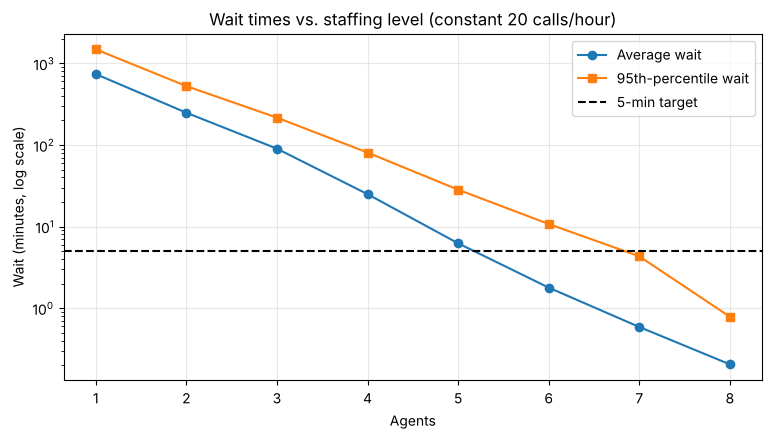

In [5]:
fig, ax = plt.subplots()
ax.plot(staffing.index, staffing["Avg wait (min)"], "o-", label="Average wait")
ax.plot(staffing.index, staffing["95th-pct wait (min)"], "s-", label="95th-percentile wait")
ax.axhline(WAIT_TARGET_MIN, color="k", linestyle="--", label=f"{WAIT_TARGET_MIN}-min target")
ax.set_yscale("log")
ax.set_xlabel("Agents")
ax.set_ylabel("Wait (minutes, log scale)")
ax.set_title("Wait times vs. staffing level (constant 20 calls/hour)")
ax.legend()
plt.show()

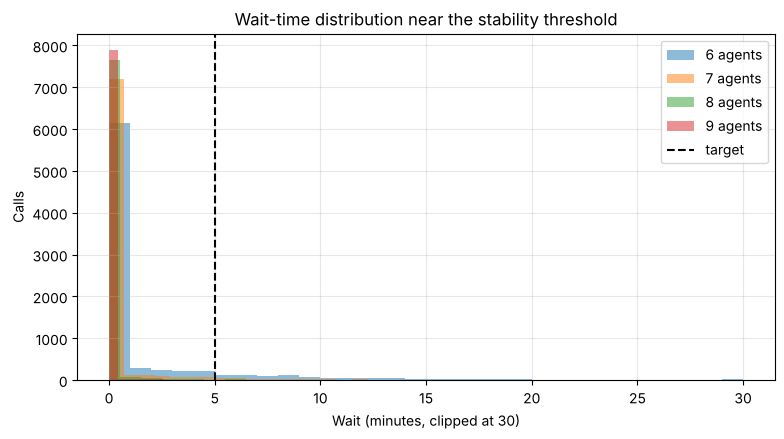

In [6]:
fig, ax = plt.subplots()
for s in range(max(best_s or 5, 5) - 1, max(best_s or 5, 5) + 3):
    waits = np.concatenate([w for w, _, _ in replicate(s, CONSTANT, n_reps=50)])
    ax.hist(np.clip(waits, 0, 30), bins=30, alpha=0.5, label=f"{s} agents")
ax.axvline(WAIT_TARGET_MIN, color="k", linestyle="--", label="target")
ax.set_xlabel("Wait (minutes, clipped at 30)")
ax.set_ylabel("Calls")
ax.set_title("Wait-time distribution near the stability threshold")
ax.legend()
plt.show()

## 4. Time-varying demand

Demand is not flat: 30 calls/hour in hours 0–2, 20 in hours 2–6 and 40 in hours 6–8. Peaks of 30 and 40 calls/hour need more than 6 and 8 agents respectively just to be stable, so a constant crew sized for the average is a poor fit.

In [7]:
PERIODS_TV = [(0, 2, 30), (2, 6, 20), (6, 8, 40)]

tv = {s: summarise(replicate(s, PERIODS_TV)) for s in range(3, 13)}
tv = pd.DataFrame(tv).T.rename_axis("Agents").drop(columns="Abandon rate")
print(tv.round(2))

tv_ok = tv[tv["95th-pct wait (min)"] <= WAIT_TARGET_MIN]
if len(tv_ok):
    print(f"\nConstant crew needed for the 5-min target under time-varying demand: {int(tv_ok.index[0])} agents")

        Avg wait (min)  95th-pct wait (min)
Agents                                     
3               187.25               421.45
4                79.30               207.22
5                29.56                93.34
6                12.19                48.83
7                 5.85                29.04
8                 2.84                17.07
9                 1.34                 9.33
10                0.62                 4.59
11                0.28                 1.71
12                0.12                 0.00

Constant crew needed for the 5-min target under time-varying demand: 10 agents


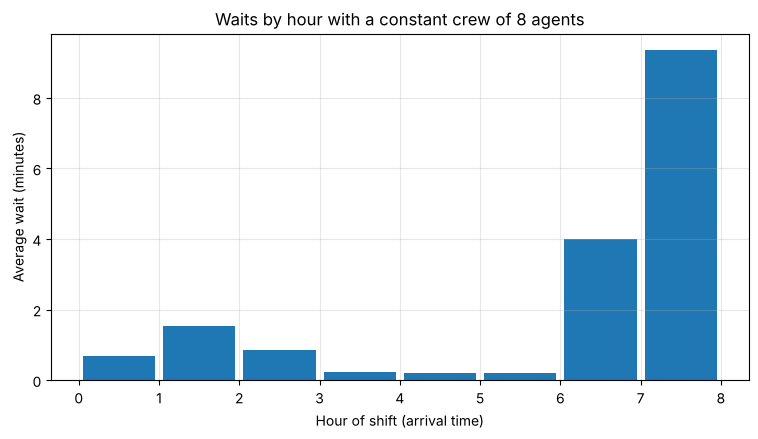

In [8]:
# Where in the shift do callers wait? (average wait by hour of arrival)
s_demo = 8
hourly = []
for r in range(N_REPS):
    rng = np.random.default_rng([SEED, r])
    arr, svc = generate_calls(rng, PERIODS_TV)
    w, _ = run_queue(arr, svc, s_demo)
    hourly.append(pd.DataFrame({"hour": arr.astype(int), "wait_min": w * 60}))
hourly = pd.concat(hourly).groupby("hour")["wait_min"].mean()

fig, ax = plt.subplots()
ax.bar(hourly.index + 0.5, hourly.values, width=0.9)
ax.set_xlabel("Hour of shift (arrival time)")
ax.set_ylabel("Average wait (minutes)")
ax.set_title(f"Waits by hour with a constant crew of {s_demo} agents")
plt.show()

## 5. Caller abandonment

Callers hang up if they would have to wait longer than their patience (5 minutes here). Abandoned calls use no agent time. Fewer agents means more lost calls, even though the waits of the calls that *are* served look short.

In [9]:
PATIENCE_H = WAIT_TARGET_MIN / 60

aband = {s: summarise(replicate(s, CONSTANT, patience=PATIENCE_H)) for s in range(1, 9)}
aband = pd.DataFrame(aband).T.rename_axis("Agents")
aband["Abandon rate"] = (aband["Abandon rate"] * 100).round(1)
aband.rename(columns={"Abandon rate": "Abandon rate (%)",
                      "Avg wait (min)": "Avg wait, served (min)",
                      "95th-pct wait (min)": "95th-pct wait, served (min)"}).round(2)

,"Avg wait, served (min)","95th-pct wait, served (min)",Abandon rate (%)
Agents,,,
1,2.27,4.79,76.4
2,1.88,4.74,54.4
3,1.47,4.63,35.5
4,1.05,4.42,20.6
5,0.67,3.96,10.6
6,0.40,3.23,4.8
7,0.20,1.79,1.9
8,0.10,0.05,0.7


## 6. Agent breaks

One agent takes a break starting at hour 3. Both scenarios use the *same* simulated calls (common random numbers), so differences come from the break alone.

In [10]:
def break_experiment(s, break_start, length_h, n_reps=N_REPS):
    base, with_break = [], []
    for r in range(n_reps):
        rng = np.random.default_rng([SEED, r])
        arr, svc = generate_calls(rng, CONSTANT)
        base.append(np.nanmean(run_queue(arr, svc, s)[0]) * 60)
        brk = {0: (break_start, break_start + length_h)}
        with_break.append(np.nanmean(run_queue(arr, svc, s, breaks=brk)[0]) * 60)
    return np.mean(base), np.mean(with_break)


rows = []
for s in [6, 7, 8]:
    for length in [0.25, 0.5]:
        b, wb = break_experiment(s, break_start=3, length_h=length)
        rows.append({"Agents": s, "Break (min)": int(length * 60),
                     "Avg wait, no break (min)": b, "Avg wait, with break (min)": wb,
                     "Increase (min)": wb - b})
pd.DataFrame(rows).round(2)

,Agents,Break (min),"Avg wait, no break (min)","Avg wait, with break (min)",Increase (min)
0,6,15,1.72,1.75,0.03
1,6,30,1.72,1.82,0.10
2,7,15,0.56,0.57,0.01
3,7,30,0.56,0.59,0.03
4,8,15,0.20,0.20,0.00
5,8,30,0.20,0.20,0.01


## 7. Cost optimisation

Total cost per shift = agent wages + the cost of customer waiting time.

| Parameter | Value |
|---|---|
| Agent wage | $20 per hour |
| Waiting cost | $0.50 per caller-minute |

        Staffing ($)  Waiting ($)  Total ($)
Agents                                      
5              800.0        503.0     1303.0
6              960.0        144.0     1104.0
7             1120.0         47.0     1167.0
8             1280.0         16.0     1296.0
9             1440.0          6.0     1446.0
10            1600.0          2.0     1602.0
11            1760.0          1.0     1761.0
12            1920.0          0.0     1920.0

Cost-minimising crew: 6 agents


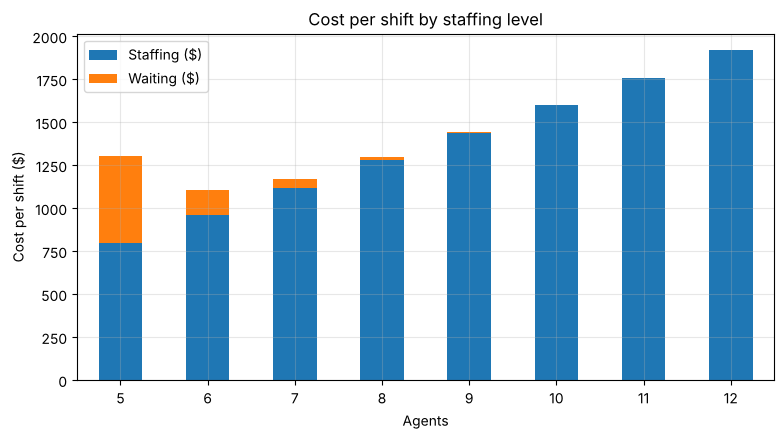

In [11]:
C_AGENT = 20.0    # $ per agent-hour
C_WAIT = 0.50     # $ per caller-minute of waiting

cost_rows = []
for s in range(5, 13):
    reps = replicate(s, CONSTANT)
    wait_cost = np.mean([w.sum() * C_WAIT for w, _, _ in reps])
    staff_cost = s * C_AGENT * SHIFT_HOURS
    cost_rows.append({"Agents": s, "Staffing ($)": staff_cost, "Waiting ($)": wait_cost,
                      "Total ($)": staff_cost + wait_cost})
costs = pd.DataFrame(cost_rows).set_index("Agents")
opt_s = int(costs["Total ($)"].idxmin())
print(costs.round(0))
print(f"\nCost-minimising crew: {opt_s} agents")

ax = costs[["Staffing ($)", "Waiting ($)"]].plot.bar(stacked=True, figsize=(9, 4.5))
ax.set_ylabel("Cost per shift ($)")
ax.set_title("Cost per shift by staffing level")
plt.xticks(rotation=0)
plt.show()

## 8. Day-to-day variability

A staffing level that meets the target *on average* can still miss it on individual days. Here we simulate 30 consecutive shifts with the cost-optimal crew.

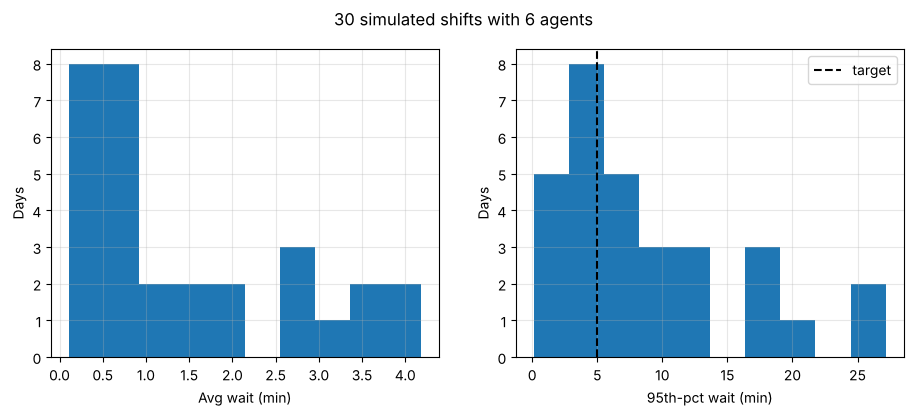

Days meeting the 5-minute 95th-percentile target: 12/30


,Avg wait (min),95th-pct wait (min)
count,30.00,30.00
mean,1.44,8.72
std,1.25,7.25
min,0.11,0.11
25%,0.46,3.59
50%,0.82,5.83
75%,2.42,12.63
max,4.18,27.18


In [12]:
daily = []
for day in range(30):
    rng = np.random.default_rng([SEED, 2024, day])
    arr, svc = generate_calls(rng, CONSTANT)
    w = run_queue(arr, svc, opt_s)[0] * 60
    daily.append({"Avg wait (min)": w.mean(), "95th-pct wait (min)": np.percentile(w, 95)})
daily = pd.DataFrame(daily)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, daily.columns):
    ax.hist(daily[col], bins=10)
    ax.set_xlabel(col)
    ax.set_ylabel("Days")
axes[1].axvline(WAIT_TARGET_MIN, color="k", linestyle="--", label="target")
axes[1].legend()
fig.suptitle(f"30 simulated shifts with {opt_s} agents")
plt.show()

days_ok = (daily["95th-pct wait (min)"] <= WAIT_TARGET_MIN).sum()
print(f"Days meeting the 5-minute 95th-percentile target: {days_ok}/30")
daily.describe().round(2)

## 9. Limitations and extensions

- Arrivals are Poisson and service times exponential; real calls often have heavier-tailed durations.
- Abandonment uses a fixed patience of 5 minutes; a random patience distribution would be more realistic.
- Each shift starts with an empty queue, which slightly understates waits compared with steady state.
- Natural extensions: skill-based routing, call-backs, shift schedules that vary the crew by hour.